# Conformal prediction under distribution shift

Split conformal methods pool the last `n_windows` calibration errors and take one quantile of them. That
works when future errors look like past errors. When the error scale changes (a volatility jump, a new regime),
the pooled quantile reacts slowly because most of the calibration windows still describe the old regime.

**Conformal PID control** ([Angelopoulos, Candes & Tibshirani, 2023](https://arxiv.org/abs/2307.16895)) replays the same
calibration windows in time order and *tracks* the error quantile online: a proportional step moves it after every
miss, and an integral term reacts to accumulated miscoverage. In `foundationforecast` it is a method object:
`ConformalIntervals(method=PID(...))`.

This notebook backtests both on the same point forecasts, with and without an injected volatility shift, and
reports where PID helps and what it costs. For the other conformal methods see the
[conformal prediction example](conformal-prediction.ipynb) and the
[conformal prediction guide](../conformal-prediction.md).

In [ ]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

## Load the data

**Dataset:** [M4 Hourly](https://www.sciencedirect.com/science/article/pii/S0169207019301128). We keep 24 series
with the full 1008 observations: enough history for 20 calibration windows plus 16 evaluation windows of 24 hours.

In [ ]:
import numpy as np
import pandas as pd

from foundationforecast import PID, ConformalIntervals, FoundationForecast
from foundationforecast.models import Chronos

H, N_EVAL, N_CAL, level = 24, 16, 20, [80, 95]

df = pd.read_parquet(
    "https://timecopilot.s3.amazonaws.com/public/data/m4-hourly.parquet"
)
n_obs = df.groupby("unique_id")["y"].transform("size")
df = df[n_obs == 1008]
df = df[df["unique_id"].isin(df["unique_id"].unique()[:24])]
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)
df["unique_id"].nunique(), len(df)

(24, 24192)

## Inject a volatility shift

M4 Hourly has no labelled regime change, so we create one. The last `N_EVAL * H` observations of every series, which
are exactly the evaluation windows, get Gaussian noise with a standard deviation of 3 times the noise scale of the
clean series (estimated from 24-hour differences before the shift). The first evaluation window is calibrated
entirely on the old regime. Later windows see a growing share of shifted calibration errors.

This stresses calibration only; the point forecaster is unchanged and the noise is also visible in its context.

In [ ]:
def add_volatility_shift(data, n_last, scale, seed=0):
    rng = np.random.default_rng(seed)
    out = data.copy()
    for idx in out.groupby("unique_id").groups.values():
        y = out.loc[idx, "y"]
        sd = (y.iloc[:-n_last] - y.iloc[:-n_last].shift(24)).std() / np.sqrt(2)
        tail = idx[-n_last:]
        out.loc[tail, "y"] += rng.normal(0, scale * sd, len(tail))
    return out


shifted_df = add_volatility_shift(df, n_last=N_EVAL * H, scale=3.0)

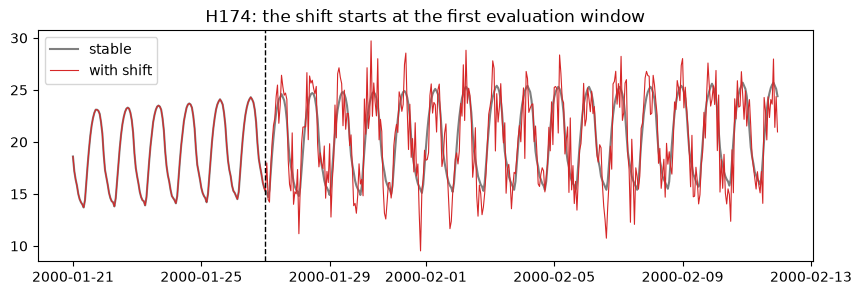

In [ ]:
import matplotlib.pyplot as plt

noise = (shifted_df["y"] - df["y"]).groupby(df["unique_id"]).std()
uid = (noise / df.groupby("unique_id")["y"].std()).idxmax()  # most visible shift
clean = df[df["unique_id"] == uid].iloc[-(N_EVAL + 6) * H :]
noisy = shifted_df[shifted_df["unique_id"] == uid].iloc[-(N_EVAL + 6) * H :]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(clean["ds"], clean["y"], label="stable", color="tab:gray")
ax.plot(noisy["ds"], noisy["y"], label="with shift", color="tab:red", lw=0.8)
ax.axvline(noisy["ds"].iloc[-N_EVAL * H], color="k", ls="--", lw=1)
ax.set_title(f"{uid}: the shift starts at the first evaluation window")
ax.legend()
plt.show()

## Calibrators

All four models share the same point forecaster (Chronos-Bolt small), the same 20 calibration windows and the same
non-overlapping 24-hour step; only the calibration method differs.

- `conformal_distribution` and `conformal_error`: pooled split conformal (library defaults).
- `PID()`: quantile tracking plus error integration, asymmetric tails.
- `PID(integrate=False)`: quantile tracking only.

Each evaluation window is calibrated only on windows that ended before its cutoff, and PID's replay only uses
errors that had already been revealed at each step (the error at horizon step `j` is revealed `j` observations after
its window's cutoff), so nothing from the future is used.

In [ ]:
settings = {
    "conformal_distribution": ConformalIntervals(
        n_windows=N_CAL, method="conformal_distribution", step_size=H
    ),
    "conformal_error": ConformalIntervals(
        n_windows=N_CAL, method="conformal_error", step_size=H
    ),
    "PID": ConformalIntervals(n_windows=N_CAL, method=PID(), step_size=H),
    "PID-no-integrator": ConformalIntervals(
        n_windows=N_CAL, method=PID(integrate=False), step_size=H
    ),
}
ff = FoundationForecast(
    models=[
        Chronos(repo_id="amazon/chronos-bolt-small", alias=alias, prediction_intervals=ci)
        for alias, ci in settings.items()
    ]
)

## Backtest

`cross_validation()` runs 16 rolling 24-hour evaluation windows per series. We run it on the stable data and on the shifted
data.

In [ ]:
def backtest(data):
    cv = ff.cross_validation(
        df=data, h=H, n_windows=N_EVAL, step_size=H, freq="h", level=level
    )
    cv["window"] = cv.groupby("unique_id")["cutoff"].rank(method="dense").astype(int)
    return cv


cv_stable = backtest(df)
cv_shift = backtest(shifted_df)

## Evaluation

**Coverage** is the share of actuals inside the interval; a calibrated \(L\)% interval should cover about \(L\)%.
**MSIS** is the mean scaled interval score (Gneiting & Raftery; lower is better): interval width plus a penalty
proportional to \(2/\alpha\) for every unit an actual falls outside, scaled by each series' seasonal-naive MAE
(24-hour lag, from the stable series). It rewards narrow intervals only if they still cover.

In [ ]:
scale = df.groupby("unique_id")["y"].apply(lambda s: s.diff(24).abs().mean())


def summarize(cv, scenario):
    rows = []
    s = cv["unique_id"].map(scale)
    for alias in settings:
        for lv in level:
            lo, hi, y = cv[f"{alias}-lo-{lv}"], cv[f"{alias}-hi-{lv}"], cv["y"]
            width = (hi - lo) / s
            miss = (np.maximum(lo - y, 0) + np.maximum(y - hi, 0)) / s
            rows.append(
                {
                    "scenario": scenario,
                    "method": alias,
                    "level": lv,
                    "coverage": y.between(lo, hi).mean(),
                    "msis": (width + 2 / (1 - lv / 100) * miss).mean(),
                }
            )
    return pd.DataFrame(rows)


summary = pd.concat([summarize(cv_stable, "stable"), summarize(cv_shift, "shift")])
cols = ["scenario", "level"]
order = list(settings)
summary.pivot_table(index="method", columns=cols, values="coverage").loc[order].round(3)

scenario                shift        stable       
level                      80     95     80     95
method                                            
conformal_distribution  0.567  0.768  0.728  0.883
conformal_error         0.573  0.772  0.734  0.885
PID                     0.739  0.924  0.843  0.967
PID-no-integrator       0.534  0.641  0.707  0.803

In [ ]:
summary.pivot_table(index="method", columns=cols, values="msis").loc[order].round(2)

scenario               shift        stable      
level                     80     95     80    95
method                                          
conformal_distribution  8.88  15.66   4.06  5.64
conformal_error         8.83  15.52   4.05  5.62
PID                     8.95  12.22   3.69  5.31
PID-no-integrator       8.73  20.95   3.46  6.07

**Reading the results:**
- **Under the shift, the pooled methods miss their targets.** `conformal_distribution` and `conformal_error` cover 57% at the
  80% level and 77% at 95%, because most of their 20 calibration windows describe the old, quieter regime.
- **`PID()` recovers most of the gap**: 74% and 92% coverage. At 95% its MSIS is about 21% lower than the pooled methods
  (12.2 vs 15.5). At 80% the MSIS is about the same (8.95 vs 8.83): PID buys coverage with wider intervals, and
  there the narrower intervals' misses cost as much as the extra width.
- **The integral term is what does the work.** `PID(integrate=False)` tracks the quantile with the proportional step alone,
  and is no better than the pooled methods at the shift (53% / 64% coverage, and the worst 95% MSIS, 21.0).
- **On the stable data PID is not better calibrated, only different.** The pooled methods undercover here
  (73% / 88%) and `PID()` overcovers (84% / 97%) with a lower MSIS (3.69 vs 4.05 at 80%). Without a shift the integral term
  still pushes thresholds up when the pooled windows miss, so check the achieved coverage on your own backtests
  before relying on it.

These are descriptive results on a synthetic shift, one point forecaster and 24 series, not a coverage guarantee.

## Coverage by evaluation window

The averages hide the dynamics. Here is the coverage of each evaluation window, averaged over series and horizon
steps. In the shifted run window 1 is calibrated on the old regime only.

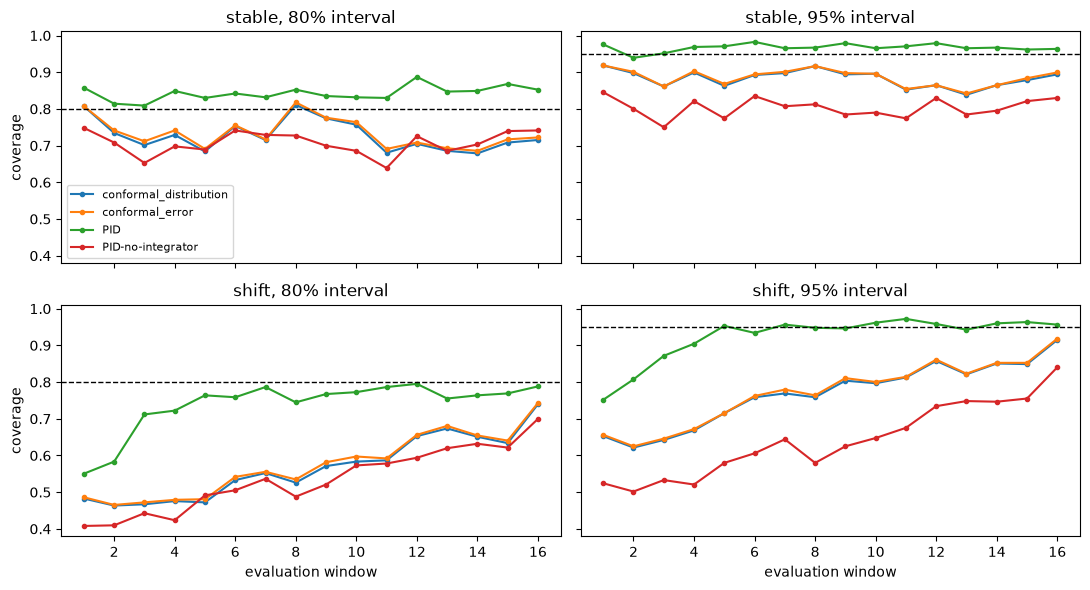

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for r, (name, cv) in enumerate([("stable", cv_stable), ("shift", cv_shift)]):
    for c, lv in enumerate(level):
        ax = axes[r, c]
        for alias in settings:
            lo, hi = cv[f"{alias}-lo-{lv}"], cv[f"{alias}-hi-{lv}"]
            cov = cv["y"].between(lo, hi).groupby(cv["window"]).mean()
            ax.plot(cov.index, cov.values, marker="o", ms=3, label=alias)
        ax.axhline(lv / 100, color="k", ls="--", lw=1)
        ax.set_title(f"{name}, {lv}% interval")
axes[1, 0].set_xlabel("evaluation window")
axes[1, 1].set_xlabel("evaluation window")
axes[0, 0].set_ylabel("coverage")
axes[1, 0].set_ylabel("coverage")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the plot:**
- Shifted data (bottom row): `PID()` moves to nominal coverage within roughly 3 to 5 evaluation windows (about 3 to 5 days) and stays
  near it. The pooled methods recover only as shifted windows fill their 20-window pool, and are still below nominal
  at window 16.
- Stable data (top row): the curves are flat. `PID()` sits above nominal, the pooled methods below, and
  `PID(integrate=False)` tracks the pooled methods at 80% and is below them at 95%.
- Window 1 of the shifted run is calibrated on the old regime only, so no method can know about the shift yet. `PID()` is
  better there (75% vs 65% at 95%) because its replay of the last windows is not pooled.
  The first miss costs, then PID reacts.

## Using PID in practice

```python
from foundationforecast import PID, ConformalIntervals

ConformalIntervals(n_windows=20, method=PID(lr=0.1))
```

| Parameter | What it does |
| --- | --- |
| `lr` | Learning rate of the quantile tracking step (default `0.1`). Higher reacts faster and is noisier. |
| `integrate` | Include the error-integration term (default `True`). It is the part that reacts to a persistent shift. |
| `symmetric` | `False` (default) tracks each tail separately, so intervals can be asymmetric; `True` tracks absolute errors. |
| `Tg`, `Csat`, `KI` | Integrator saturation and scale. Raise `Tg` or `Csat` if the integrator saturates. |
| `ncal` | Windows used to warm start the threshold (default `n_windows // 2`). |

- Use enough calibration windows. With few windows, a high level (95%) can saturate the integrator: some bounds become infinite
  and `forecast()` emits a `UserWarning`. Add windows, raise `Tg`/`Csat`, or set `integrate=False`.
- Feedback is delayed: with `step_size < h`, a window's errors are only used after they would have been observable, so `cross_validation()`
  results do not leak the future.
- The implementation is cross-checked against R's `conformalForecast::pid`. See the
  [conformal prediction guide](../conformal-prediction.md#conformal-pid-control-under-distribution-shift) for the update equations and verification.